In [1]:
import pandas as pd

In [2]:
import sys
sys.path.append('../')

%load_ext autoreload
%autoreload 2

from libs import ios
from libs.bibs import aps
from libs import vis
from libs.inference import categorical
from libs.inference import numeric
from libs import constants
from libs import utils
from libs import tools_comparison as tc

Total combinations of features: 1023


# Setup

In [3]:
vis.sns_reset()
vis.sns_paper_style()

## Constants

In [4]:

FN_APS_DEMOGRAPHICS = '/data/datasets/APS/aps_data_processing/shares/aps-2022_25-10-01_e59319256d553035c40188457bb16edbfe02da04.zip' #aps_20240130_2e52fdd7260ea462878821948a2a463ed9acb58a.zip'

VERSION = 3
FN_CNKI_GIVENNAMES_GENDER = f'../../results/v{VERSION}/gender/pinyin_infer/uniqueChineseAllGivenNames_PYgender.csv'
FN_CNKI_GROUND_TRUTH = f'../../data/v{VERSION}/annotations/gender/{constants.FN_ANNOTATIONS}'

In [5]:
RESULTS_DIR = f'../../results/v{VERSION}/APS/'
ios.validate_path(RESULTS_DIR)

In [6]:
FN_APS_CLEAN_CH_PY = ios.path_join(RESULTS_DIR, 'data_aps_clean_ch_py.csv')
FN_APS_OA_CLEAN_CH_PY = ios.path_join(RESULTS_DIR, 'data_aps_oa_clean_ch_py.csv')

In [7]:
GT_METRICS = {'regression': 'mean', 'classification': 'median'}

METHOD_LABELS = {
        "gender_clean": "Karimi et al. (2016)",
        "gender_nq_clean": "Buskirk et al. (2023)",
        "pred_label": "Ours",
        "majority_label": "Ours (majority vote)",
        'pred': 'Ours',
        "gender": "Ground-truth",
    }

PINYIN_AGG_LABELS = {'gender_avg_all': 'Mean (all chars)', 
                     'gender_weighted_pop_NU': 'Weighted pop.', 
                     'gender_avg_CNKI': 'Mean (CNKI chars)', 
                     'gender_weighted_pop_CNKI': 'Weighted CNKI pop.'}

## Loading data

In [8]:
_df_aps_authors = ios.read_csv_from_zip(FN_APS_DEMOGRAPHICS, 'data/authors.csv')
_df_aps_authors_names = ios.read_csv_from_zip(FN_APS_DEMOGRAPHICS, 'data/author_names.csv')
_df_aps_genders = ios.read_csv_from_zip(FN_APS_DEMOGRAPHICS, 'data/genders.csv')

df_aps = pd.merge(_df_aps_authors, _df_aps_authors_names, how='inner', on='id_author', suffixes=("_a","_n"))
df_aps = pd.merge(df_aps, _df_aps_genders, how='left', on='id_gender')
df_aps = df_aps[['id_author','id_author_name','name','gender','gender_nq', 'disambiguated']] # NOTE: it contains disambiguated True and False

print(f"APS authors: {_df_aps_authors.shape}")
print(f"APS authors names: {_df_aps_authors_names.shape}")
print(f"APS genders: {_df_aps_genders.shape}")
print(f"APS all authors merged: {df_aps.shape}")


APS authors: (874556, 4)
APS authors names: (948771, 4)
APS genders: (3, 2)
APS all authors merged: (948771, 6)


In [9]:
df_cnki_gender = pd.read_csv(FN_CNKI_GIVENNAMES_GENDER)
print(f"CNKI given names with gender: {df_cnki_gender.shape}")


CNKI given names with gender: (46144, 18)


In [10]:
df_aps.sample(5)

,id_author,id_author_name,name,gender,gender_nq,disambiguated
933932,859717,933932,T. E. Toohig,unknown,-,False
883006,808791,883006,R. E. Marrs,unknown,-,False
940687,866472,940687,J. Raasch,unknown,-,False
63233,50007,63233,Sumit R. Das,male,gm,True
277598,221537,277598,V. Natoli,male,-,True


In [11]:
df_cnki_gender.sample(5)

,givenname,pred,pred_label,pop_CNKI,pop_NU,NLen,english_one,unique_name_count,gender_weighted_pop_CNKI,gender_weighted_pop_NU,gender_avg_all,gender_avg_CNKI,male_label_count,female_label_count,neutral_label_count,pop_sum_CNKI,pop_sum_NU,givennames
25622,成明,0.159080,male,10,14892.610777,2,chengming,5,0.160190,0.160380,0.161866,0.161866,5,0,0,16,24317.005658,成名#成明#承铭#澄明#程明
41030,行九,0.168321,male,1,511.271270,2,hangjiu,1,0.168321,0.168321,0.168321,0.168321,1,0,0,1,511.271270,行九
43009,重秀,0.693138,female,2,1949.742743,2,zhongxiu,2,0.627623,0.598962,0.638542,0.638542,0,2,0,5,14177.997719,忠秀#重秀
8903,东硕,0.160646,male,1,2577.101431,2,dongshuo,1,0.160646,0.160646,0.160646,0.160646,1,0,0,1,2577.101431,东硕
2257,懔,0.313467,male,0,0.000001,1,lin,30,0.452012,0.349024,0.343443,0.408615,20,0,10,347,17160.591856,临#凛#吝#嶙#廪#懔#拎#林#檩#淋#潾#琳#璘#瞵#磷#箖#粼#翷#膦#蔺#赁#躏#辚#...


# Pre-processing

In [12]:
# APS
df_aps_clean = aps.clean_aps_names(df_aps)
df_aps_clean_ch_py = aps.detect_pinyin_and_chinese_names(df_aps_clean)
df_aps_clean_ch_py.shape, 

((874556, 21),)

In [13]:
df_aps_clean_ch_py.sample(5)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,gender_clean,gender_nq_clean,longest_name,longest_name_clean,givenname_clean,...,is_pinyin_givenname,is_pinyin_familyname,is_pinyin,ch_name,ch_splitname,ch_familyname,ch_givenname,ch_translated_name_in_pinyin,ch_translated_familyname_in_pinyin,ch_translated_givenname_in_pinyin
849857,849857,[I. J. Van Heerden],1,[unknown],[-],unknown,unknown,I. J. Van Heerden,i. j. van heerden,i.,...,False,False,False,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
764183,764183,[D. Céolin],1,[unknown],[-],unknown,unknown,D. Céolin,d. ceolin,d.,...,False,False,False,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
550575,550575,[M. A. McMahan],1,[unknown],[-],unknown,unknown,M. A. McMahan,m. a. mcmahan,m.,...,False,False,False,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
52399,52399,[Tsung-Wei Chen],1,[male],[gm],male,gm,Tsung-Wei Chen,tsung-wei chen,tsung-wei,...,False,True,False,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
439368,439368,[L. Veisz],1,[unknown],[-],unknown,unknown,L. Veisz,l. veisz,l.,...,False,False,False,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [14]:
# sample of chinese character names
df_aps_clean_ch_py.query("ch_name.notna() and ch_givenname.notna()").sample(2)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,gender_clean,gender_nq_clean,longest_name,longest_name_clean,givenname_clean,...,is_pinyin_givenname,is_pinyin_familyname,is_pinyin,ch_name,ch_splitname,ch_familyname,ch_givenname,ch_translated_name_in_pinyin,ch_translated_familyname_in_pinyin,ch_translated_givenname_in_pinyin
573993,573993,[Wei Hong (洪伟)],1,[unknown],[-],unknown,unknown,Wei Hong (洪伟),wei hong,wei,...,1,True,True,洪伟,[洪 伟],洪,伟,hong wei,hong,wei
513329,513329,[J. G. Wang (王建国)],1,[unknown],[-],unknown,unknown,J. G. Wang (王建国),j. g. wang,j.,...,False,True,False,王建国,[王 建国],王,建国,wang jianguo,wang,jianguo


In [15]:
# sample of pinyin names
df_aps_clean_ch_py.query("is_pinyin == True").sample(2)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,gender_clean,gender_nq_clean,longest_name,longest_name_clean,givenname_clean,...,is_pinyin_givenname,is_pinyin_familyname,is_pinyin,ch_name,ch_splitname,ch_familyname,ch_givenname,ch_translated_name_in_pinyin,ch_translated_familyname_in_pinyin,ch_translated_givenname_in_pinyin
704700,704700,[Yu Liu],1,[unknown],[-],unknown,unknown,Yu Liu,yu liu,yu,...,1,True,True,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
187394,187394,[Zhirong Jiao],1,[male],[-],male,unknown,Zhirong Jiao,zhirong jiao,zhirong,...,2,True,True,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [16]:
# select only chinese character names or pinyin names
data_aps_gender = df_aps_clean_ch_py.query("is_pinyin == True or ch_name.notna()").copy()
data_aps_gender.shape, df_aps_clean_ch_py.shape, data_aps_gender.shape[0] * 100 / df_aps_clean_ch_py.shape[0]

((43861, 21), (874556, 21), 5.015230585577139)

In [17]:
ios.to_csv(data_aps_gender, FN_APS_CLEAN_CH_PY)

# Analysis

In [18]:
data_aps_gender = ios.load_csv(FN_APS_CLEAN_CH_PY, index_col=0)
data_aps_gender.shape

(43861, 21)

In [19]:
data_aps_gender.head(2)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,gender_clean,gender_nq_clean,longest_name,longest_name_clean,givenname_clean,...,is_pinyin_givenname,is_pinyin_familyname,is_pinyin,ch_name,ch_splitname,ch_familyname,ch_givenname,ch_translated_name_in_pinyin,ch_translated_familyname_in_pinyin,ch_translated_givenname_in_pinyin
14,14,['Na Zhang'],1,['female'],['-'],female,unknown,Na Zhang,na zhang,na,...,1,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15,15,"['Ning Zhang', 'Ningyu Zhang']",2,"['female', 'female']","['-', '-']",female,unknown,Ningyu Zhang,ningyu zhang,ningyu,...,2,True,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
df_cnki_gender_unique_pinyins = df_cnki_gender.drop_duplicates(subset=['english_one'], keep='first').copy()
df_cnki_gender_unique_pinyins.loc[:, 'majority_label'] = df_cnki_gender_unique_pinyins.apply(lambda row: categorical.infer_gender_by_majority_vote(row.male_label_count, row.female_label_count, row.neutral_label_count), axis=1)
df_cnki_gender_unique_pinyins.shape

(18740, 19)

In [21]:
df_cnki_gender_unique_pinyins.head(2)

,givenname,pred,pred_label,pop_CNKI,pop_NU,NLen,english_one,unique_name_count,gender_weighted_pop_CNKI,gender_weighted_pop_NU,gender_avg_all,gender_avg_CNKI,male_label_count,female_label_count,neutral_label_count,pop_sum_CNKI,pop_sum_NU,givennames,majority_label
0,㑇,0.313467,male,0,0.000001,1,zhou,28,0.296593,0.296017,0.310476,0.296375,28,0,0,35,2046.707801,㑇#周#咒#啁#妯#婤#宙#州#帚#昼#洲#皱#碡#籀#粥#纣#绉#肘#胄#舟#荮#诌#赒#...,male
1,㑊,0.313467,male,0,0.000001,1,yi,133,0.388524,0.433901,0.367037,0.414925,79,4,50,497,21036.168984,㑊#一#乂#义#乙#亦#亿#仡#以#仪#伊#佁#佚#佾#依#倚#刈#劓#勚#匜#医#呓#咦#...,male


In [22]:
gender_score_cols = ['gender_avg_all', 'gender_weighted_pop_NU', 'gender_avg_CNKI', 'gender_weighted_pop_CNKI']

## Chinese characters

In [23]:
cols = ['givenname', 'pred', 'pred_label'] + gender_score_cols
data_aps_gender_chinese = data_aps_gender.query("ch_givenname.notna()").copy()
data_aps_gender_chinese = data_aps_gender_chinese.merge(df_cnki_gender[cols], 
                                                how='left', 
                                                left_on='ch_givenname', 
                                                right_on='givenname', 
                                                suffixes=("_ours", "_cnki"))


data_aps_gender_chinese.shape

(3165, 28)

In [24]:
data_aps_gender_chinese.head(2)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,gender_clean,gender_nq_clean,longest_name,longest_name_clean,givenname_clean,...,ch_translated_name_in_pinyin,ch_translated_familyname_in_pinyin,ch_translated_givenname_in_pinyin,givenname,pred,pred_label,gender_avg_all,gender_weighted_pop_NU,gender_avg_CNKI,gender_weighted_pop_CNKI
0,232,['Wun-Hao Kang (康文豪)'],1,['unknown'],['-'],unknown,unknown,Wun-Hao Kang (康文豪),wun-hao kang,wun-hao,...,kang wenhao,kang,wenhao,文豪,0.15908,male,0.226337,0.160556,0.226337,0.16984
1,294,"['Y. Liu', 'Y. Q. Liu', 'Y. Liu (刘育)', 'Y. L. ...",5,"['male', 'male', 'male', 'male', 'male']","['-', '-', '-', '-', '-']",male,unknown,Y. Liu (刘泱杰),y. liu,y.,...,liu yangjie,liu,yangjie,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
data_aps_gender_chinese.loc[:, 'gender_nq_clean'] = data_aps_gender_chinese.gender_nq_clean.replace({'gf': 'female', 'gm': 'male'})
data_aps_gender_chinese.loc[:, 'pred_label'] = data_aps_gender_chinese.pred_label.replace({pd.NA: 'unknown'})
data_aps_gender_chinese.gender_clean.unique(), data_aps_gender_chinese.gender_nq_clean.unique(), data_aps_gender_chinese.pred_label.unique()

(array(['unknown', 'male', 'female'], dtype=object),
 array(['unknown', 'male', 'female'], dtype=object),
 array(['male', 'unknown', 'neutral', 'female'], dtype=object))

### Our predictions

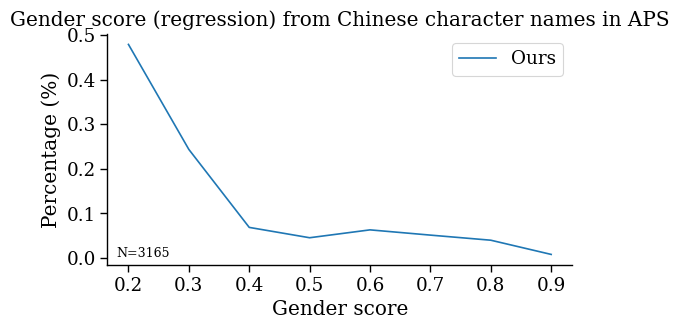

In [26]:
vis.plot_gender_distributions(data_aps_gender_chinese, 
                          cols = ['pred'],
                          figsize = (6, 3),
                          title = "Gender score (regression) from Chinese character names in APS",
                          label_mapping=METHOD_LABELS,
                          )
vis.plt.show()
vis.plt.close()

### Comparison with other methods

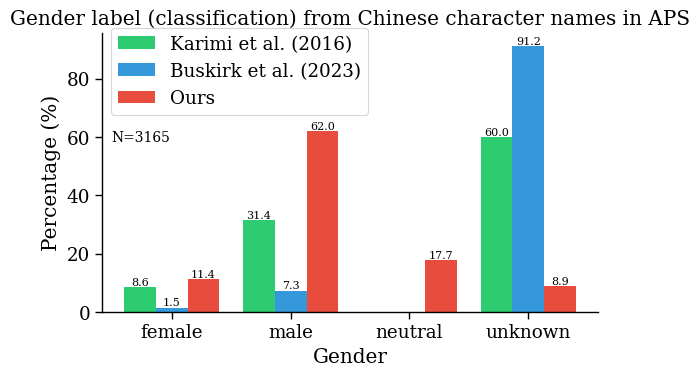

In [27]:
fig, ax = vis.plot_gender_comparison(
    data_aps_gender_chinese,
    method_order=["gender_clean", "gender_nq_clean", "pred_label"],
    method_labels=METHOD_LABELS,
    xlabel_order=["female", "male", "neutral", "unknown"],
    colors=["#2ecc71", "#3498db", "#e74c3c"],
    use_percentages=True,
    annotate_bars=True,
    title="Gender label (classification) from Chinese character names in APS",
    n_annotation_kwargs={"fontsize": 10, "x": 0.02, "y":0.65, "ha": "left"} ,
    legend_kwargs={"loc": "upper left", "bbox_to_anchor": (0.0, 1.05)}
)
vis.plt.show()
vis.plt.close()

In [28]:
# Agreement between gender inference methods provided by APS and ours
method_cols = ["gender_clean", "gender_nq_clean", "pred_label"]
# df = data_aps_gender_chinese[method_cols].dropna(how="any")

# 1) Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:
agreement_ch = categorical.pairwise_agreement(data_aps_gender_chinese, method_cols)
print("Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:")
display(agreement_ch.round(2))

# 2) Cohen's Kappa — agreement corrected for chance
kappa_ch = categorical.pairwise_kappa(data_aps_gender_chinese, method_cols)
print("\nCohen's Kappa matrix (chance-corrected agreement):")
display(kappa_ch.round(2))

Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:


,gender_clean,gender_nq_clean,pred_label
gender_clean,1.00,0.64,0.23
gender_nq_clean,0.64,1.00,0.12
pred_label,0.23,0.12,1.00



Cohen's Kappa matrix (chance-corrected agreement):


,gender_clean,gender_nq_clean,pred_label
gender_clean,1.00,0.15,-0.04
gender_nq_clean,0.15,1.00,-0.01
pred_label,-0.04,-0.01,1.00


In [29]:
pd.crosstab(data_aps_gender_chinese['gender_clean'], data_aps_gender_chinese['pred_label'], margins=True)

pred_label,female,male,neutral,unknown,All
gender_clean,,,,,
female,46,122,72,33,273
male,97,575,177,144,993
unknown,217,1266,311,105,1899
All,360,1963,560,282,3165


In [30]:
pd.crosstab(data_aps_gender_chinese['gender_nq_clean'], data_aps_gender_chinese['pred_label'], margins=True)

pred_label,female,male,neutral,unknown,All
gender_nq_clean,,,,,
female,13,12,14,7,46
male,11,127,49,45,232
unknown,336,1824,497,230,2887
All,360,1963,560,282,3165


In [31]:
pd.crosstab(data_aps_gender_chinese['gender_clean'], data_aps_gender_chinese['gender_nq_clean'], margins=True)

gender_nq_clean,female,male,unknown,All
gender_clean,,,,
female,13,45,215,273
male,25,150,818,993
unknown,8,37,1854,1899
All,46,232,2887,3165


## Pinyin

In [32]:
cols = ['english_one', 'gender_weighted_pop_CNKI', 'gender_weighted_pop_NU', 'gender_avg_all', 'gender_avg_CNKI', 'male_label_count', 'female_label_count', 'neutral_label_count', 'majority_label']
data_aps_gender_pinyin = data_aps_gender.merge(df_cnki_gender_unique_pinyins[cols], 
                                        how='left', 
                                        left_on='givenname_clean', 
                                        right_on='english_one', 
                                        suffixes=("_ours", "_cnki"))

data_aps_gender_pinyin.shape

(43861, 30)

In [33]:
# standardize the gender labels across the methods (APS gender, APS gender (nq), majority vote)
data_aps_gender_pinyin.loc[:, 'gender_nq_clean'] = data_aps_gender_pinyin.gender_nq_clean.replace({'gf': 'female', 'gm': 'male'})
data_aps_gender_pinyin.loc[:, 'majority_label'] = data_aps_gender_pinyin.majority_label.replace({pd.NA: 'unknown'})
data_aps_gender_pinyin.gender_clean.unique(), data_aps_gender_pinyin.gender_nq_clean.unique(), data_aps_gender_pinyin.majority_label.unique()

(array(['female', 'male', 'unknown'], dtype=object),
 array(['unknown', 'female', 'male', 'neutral'], dtype=object),
 array(['male', 'neutral', 'unknown', 'female'], dtype=object))

In [34]:
data_aps_gender_pinyin.head(2)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,gender_clean,gender_nq_clean,longest_name,longest_name_clean,givenname_clean,...,ch_translated_givenname_in_pinyin,english_one,gender_weighted_pop_CNKI,gender_weighted_pop_NU,gender_avg_all,gender_avg_CNKI,male_label_count,female_label_count,neutral_label_count,majority_label
0,14,['Na Zhang'],1,['female'],['-'],female,unknown,Na Zhang,na zhang,na,...,NaN,na,0.673670,0.673910,0.422870,0.650200,7.0,1.0,3.0,male
1,15,"['Ning Zhang', 'Ningyu Zhang']",2,"['female', 'female']","['-', '-']",female,unknown,Ningyu Zhang,ningyu zhang,ningyu,...,NaN,ningyu,0.475539,0.536354,0.475539,0.475539,1.0,1.0,0.0,neutral


### Our predictions

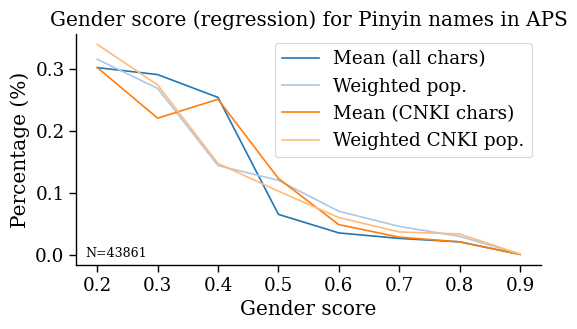

In [35]:
vis.plot_gender_distributions(data_aps_gender_pinyin, 
                          cols = gender_score_cols,
                          figsize = (6, 3),
                          title = "Gender score (regression) for Pinyin names in APS",
                          label_mapping=PINYIN_AGG_LABELS,
                          )



### Comparison with other methods 

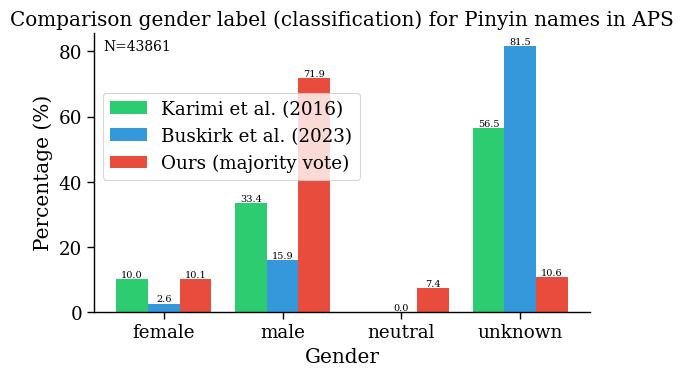

In [36]:
fig, ax = vis.plot_gender_comparison(
    data_aps_gender_pinyin,
    method_order=["gender_clean", "gender_nq_clean", "majority_label"],
    method_labels=METHOD_LABELS,
    xlabel_order=["female", "male", "neutral", "unknown"],
    use_percentages=True,
    annotate_bars=True,
    annotate_kwargs={"fontsize": 7, "ha": "center", "va": "bottom"},
    title="Comparison gender label (classification) for Pinyin names in APS",
    n_annotation_kwargs={"fontsize": 10, "x": 0.02, "y":0.98, "ha": "left"},
    legend_kwargs={"loc": "upper left", "bbox_to_anchor": (0.0, 0.82)}
)
vis.plt.show()
vis.plt.close()

In [37]:
# Agreement between gender inference methods provided by APS and ours
method_cols = ["gender_clean", "gender_nq_clean", "majority_label"]
# df = data_aps_gender_pinyin[method_cols].dropna(how="any")

# 1) Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:
agreement_py = categorical.pairwise_agreement(data_aps_gender_pinyin, method_cols)
print("Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:")
display(agreement_py.round(2))

# 2) Cohen's Kappa — agreement corrected for chance
kappa_py = categorical.pairwise_kappa(data_aps_gender_pinyin, method_cols)
print("\nCohen's Kappa matrix (chance-corrected agreement):")
display(kappa_py.round(2))

Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:


,gender_clean,gender_nq_clean,majority_label
gender_clean,1.00,0.53,0.33
gender_nq_clean,0.53,1.00,0.22
majority_label,0.33,0.22,1.00



Cohen's Kappa matrix (chance-corrected agreement):


,gender_clean,gender_nq_clean,majority_label
gender_clean,1.00,0.02,0.02
gender_nq_clean,0.02,1.00,0.02
majority_label,0.02,0.02,1.00


In [38]:
pd.crosstab(data_aps_gender_pinyin['gender_clean'], data_aps_gender_pinyin['majority_label'], margins=True)

majority_label,female,male,neutral,unknown,All
gender_clean,,,,,
female,930,2621,407,439,4397
male,1330,10735,1076,1527,14668
unknown,2180,18163,1777,2676,24796
All,4440,31519,3260,4642,43861


In [39]:
pd.crosstab(data_aps_gender_pinyin['gender_nq_clean'], data_aps_gender_pinyin['majority_label'], margins=True)

majority_label,female,male,neutral,unknown,All
gender_nq_clean,,,,,
female,272,632,73,146,1123
male,195,5708,355,710,6968
neutral,1,2,1,0,4
unknown,3972,25177,2831,3786,35766
All,4440,31519,3260,4642,43861


In [40]:
pd.crosstab(data_aps_gender_pinyin['gender_clean'], data_aps_gender_pinyin['gender_nq_clean'], margins=True)

gender_nq_clean,female,male,neutral,unknown,All
gender_clean,,,,,
female,203,590,1,3603,4397
male,318,2505,3,11842,14668
unknown,602,3873,0,20321,24796
All,1123,6968,4,35766,43861


## Ground-truth

In [41]:
df_gt = ios.load_csv(FN_CNKI_GROUND_TRUTH)
df_gt.shape

(166, 14)

In [42]:
df_gt.head(2)

,givenname,a1,a2,a3,a4,a5,a6,a7,a8,a9,a10,a11,single_char,round
0,一葳,4.0,2.0,5.0,5.0,3.0,4.0,2.0,1.0,2.0,4.0,5.0,False,1
1,丙辰,2.0,1.0,1.0,1.0,3.0,3.0,2.0,3.0,1.0,1.0,1.0,False,1


In [43]:
# adding pinyin form
df_gt.loc[:, 'pinyin_givenname'] = df_gt.givenname.apply(lambda n: utils.characternames_handler.pinyin_givename([n])[0])

# Adding the ground-truth metrics from the annotations
annotation_cols = [c for c in df_gt.columns if c.startswith('a') and type(eval(c[1:])) == int]
for _, metric in GT_METRICS.items():
    df_gt.loc[:, metric] = df_gt[annotation_cols].agg(metric, axis=1)
    df_gt.loc[:, metric] = df_gt.loc[:, metric].apply(lambda v: tc.scale_1_to_5_to_0_to_1(v))

# Adding labels (cut 4: 0.3, 0.7 using median)
df_gt.loc[:, 'gender'] = df_gt.apply(lambda row: 'male' if row['median'] < 0.3 else 'female' if row['median'] > 0.7 else 'neutral', axis=1)

# keeping those names found in the APS gender predictions
df_gt_aps = df_gt.query("givenname in @data_aps_gender.ch_givenname or pinyin_givenname in @data_aps_gender.givenname_clean").copy()

cols_aps_ch = ['givenname', 'gender_clean', 'gender_nq_clean', 'pred_label', 'pred', 'gender_avg_all', 'gender_weighted_pop_NU', 'gender_avg_CNKI', 'gender_weighted_pop_CNKI']
df_gt_aps_ch = df_gt_aps.merge(data_aps_gender_chinese[cols_aps_ch].drop_duplicates(subset=['givenname'], keep='first'),
                            left_on='givenname',
                            right_on='givenname',
                            how='left').dropna(subset=['pred'])

cols_aps_py = ['givenname_clean', 'gender_clean', 'gender_nq_clean', 'majority_label', 'gender_avg_all', 'gender_weighted_pop_NU', 'gender_avg_CNKI', 'gender_weighted_pop_CNKI']
df_gt_aps_py = df_gt_aps.merge(data_aps_gender_pinyin[cols_aps_py].drop_duplicates(subset=['givenname_clean'], keep='first'),
                            left_on='pinyin_givenname',
                            right_on='givenname_clean',
                            how='left') 

df_gt_aps_ch.shape, df_gt_aps_py.shape

((7, 26), (116, 26))

### Chinese character

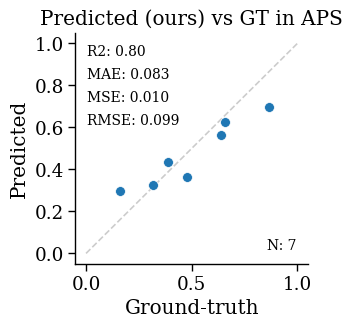

In [44]:
mae_pred_ch, mse_pred_ch, rmse_pred_ch, r2_pred_ch = numeric.get_performance(df_gt_aps_ch, 'mean', 'pred')
performance_ch = {'mae': mae_pred_ch, 'mse': mse_pred_ch, 'rmse': rmse_pred_ch, 'r2': r2_pred_ch}
_, _ = vis.plot_regression_performance(df_gt_aps_ch, 'mean', 'pred', 
                                metrics = performance_ch,
                                figsize=(3, 3), 
                                title="Predicted (ours) vs GT in APS", 
                                xlabel="Ground-truth", 
                                ylabel="Predicted",
                                markersize=50,
                                markeralpha=1.0,
                                )

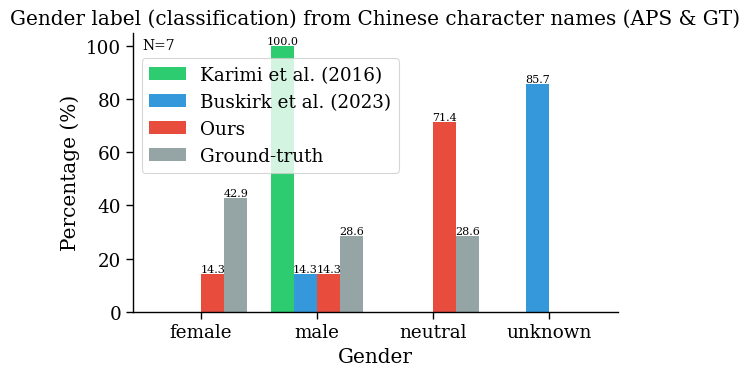

In [45]:
fig, ax = vis.plot_gender_comparison(
    df_gt_aps_ch,
    method_order=["gender_clean", "gender_nq_clean", "pred_label", 'gender'],
    method_labels=METHOD_LABELS,
    xlabel_order=["female", "male", "neutral", "unknown"],
    colors=["#2ecc71", "#3498db", "#e74c3c", "#95a5a6"],
    use_percentages=True,
    annotate_bars=True,
    title="Gender label (classification) from Chinese character names (APS & GT)",
    n_annotation_kwargs={"fontsize": 10, "x": 0.02, "y":0.98, "ha": "left"} ,
    legend_kwargs={"loc": "upper left", "bbox_to_anchor": (0.0, 0.94)}
)
vis.plt.show()
vis.plt.close()

In [46]:
# Agreement between gender inference methods provided by APS and ours
method_cols = ["gender_clean", "gender_nq_clean", "pred_label", 'gender']
# df = df_gt_aps_ch[method_cols].dropna(how="any")

# 1) Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:
agreement_gt_ch = categorical.pairwise_agreement(df_gt_aps_ch, method_cols)
print("Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:")
display(agreement_gt_ch.round(2))

# 2) Cohen's Kappa — agreement corrected for chance
kappa_gt_ch = categorical.pairwise_kappa(df_gt_aps_ch, method_cols)
print("\nCohen's Kappa matrix (chance-corrected agreement):")
display(kappa_gt_ch.round(2))

Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:


,gender_clean,gender_nq_clean,pred_label,gender
gender_clean,1.00,0.14,0.14,0.29
gender_nq_clean,0.14,1.00,0.00,0.00
pred_label,0.14,0.00,1.00,0.57
gender,0.29,0.00,0.57,1.00



Cohen's Kappa matrix (chance-corrected agreement):


/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:730: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)


,gender_clean,gender_nq_clean,pred_label,gender
gender_clean,NaN,0.00,0.00,0.00
gender_nq_clean,0.0,1.00,-0.02,-0.04
pred_label,0.0,-0.02,1.00,0.38
gender,0.0,-0.04,0.38,1.00


In [47]:
labels = ['female', 'male', 'neutral', 'unknown']
normalize = 'true' # pred, all

for col in ['gender_clean', 'gender_nq_clean', 'pred_label']:
    cm, precision, recall, f1, _, accuracy = categorical.get_performance(df_gt_aps_ch, col_true='gender', col_pred=col, labels=labels, normalize=normalize)
    
    print(f"\n========== {col} ==========")
    print("\nConfusion matrix:")
    display(cm.round(2))

    print("\nPrecision:")
    for label, prec in zip(labels, precision.round(2)):
        print(f"- {label}: {prec:.2f}")
    
    print("\nRecall:")
    for label, prec in zip(labels, recall.round(2)):
        print(f"- {label}: {prec:.2f}")
    
    
    print("\nF1 score:")
    for label, prec in zip(labels, f1.round(2)):
        print(f"- {label}: {prec:.2f}")
    

    print(f"\nAccuracy: {accuracy:.2f}")
    


========== gender_clean ==========

Confusion matrix:


array([[0., 1., 0., 0.],
       [0., 1., 0., 0.],
       [0., 1., 0., 0.],
       [0., 0., 0., 0.]])


Precision:
- female: 0.00
- male: 0.29
- neutral: 0.00
- unknown: 0.00

Recall:
- female: 0.00
- male: 1.00
- neutral: 0.00
- unknown: 0.00

F1 score:
- female: 0.00
- male: 0.44
- neutral: 0.00
- unknown: 0.00

Accuracy: 0.29

========== gender_nq_clean ==========

Confusion matrix:


array([[0.  , 0.33, 0.  , 0.67],
       [0.  , 0.  , 0.  , 1.  ],
       [0.  , 0.  , 0.  , 1.  ],
       [0.  , 0.  , 0.  , 0.  ]])


Precision:
- female: 0.00
- male: 0.00
- neutral: 0.00
- unknown: 0.00

Recall:
- female: 0.00
- male: 0.00
- neutral: 0.00
- unknown: 0.00

F1 score:
- female: 0.00
- male: 0.00
- neutral: 0.00
- unknown: 0.00

Accuracy: 0.00

========== pred_label ==========

Confusion matrix:


array([[0.33, 0.  , 0.67, 0.  ],
       [0.  , 0.5 , 0.5 , 0.  ],
       [0.  , 0.  , 1.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  ]])


Precision:
- female: 1.00
- male: 1.00
- neutral: 0.40
- unknown: 0.00

Recall:
- female: 0.33
- male: 0.50
- neutral: 1.00
- unknown: 0.00

F1 score:
- female: 0.50
- male: 0.67
- neutral: 0.57
- unknown: 0.00

Accuracy: 0.57


### Pinyin

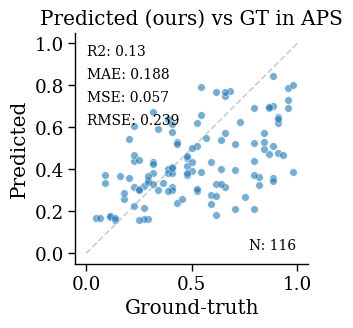

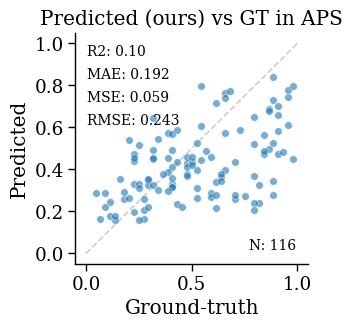

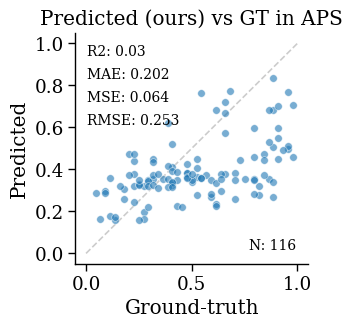

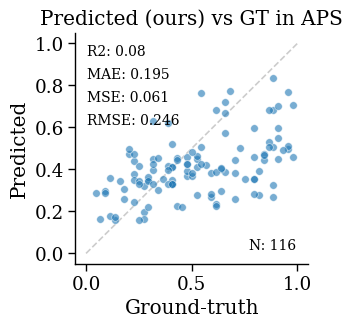

In [48]:
rmse_pred_py = None
for col in ['gender_weighted_pop_NU', 'gender_weighted_pop_CNKI', 'gender_avg_all', 'gender_avg_CNKI']:
    mae_pred, mse_pred, rmse_pred, r2_pred = numeric.get_performance(df_gt_aps_py, 'mean', col)
    performance_py = {'mae': mae_pred, 'mse': mse_pred, 'rmse': rmse_pred, 'r2': r2_pred}

    if rmse_pred_py is None:
        rmse_pred_py = (rmse_pred, col)
    elif rmse_pred < rmse_pred_py[0]:
        rmse_pred_py = (rmse_pred, col)

    _, _ = vis.plot_regression_performance(df_gt_aps_py, 'mean', col, 
                                    metrics = performance_py,
                                    figsize=(3, 3), 
                                    title="Predicted (ours) vs GT in APS", 
                                    xlabel="Ground-truth", 
                                    ylabel="Predicted",
                                    markersize=30,
                                    markeralpha=0.6,
                                    )

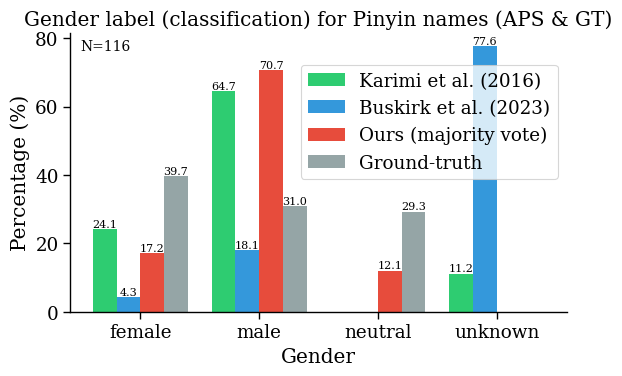

In [49]:
fig, ax = vis.plot_gender_comparison(
    df_gt_aps_py,
    method_order=["gender_clean", "gender_nq_clean", "majority_label", 'gender'],
    method_labels=METHOD_LABELS,
    xlabel_order=["female", "male", "neutral", "unknown"],
    colors=["#2ecc71", "#3498db", "#e74c3c", "#95a5a6"],
    use_percentages=True,
    annotate_bars=True,
    title="Gender label (classification) for Pinyin names (APS & GT)",
    n_annotation_kwargs={"fontsize": 10, "x": 0.02, "y":0.98, "ha": "left"},
    legend_kwargs={"loc": "upper right", "bbox_to_anchor": (1.0, 0.92)}
)
vis.plt.show()
vis.plt.close()

In [50]:
# Agreement between gender inference methods provided by APS and ours
method_cols = ["gender_clean", "gender_nq_clean", "majority_label", 'gender']
# df = df_gt_aps_py[method_cols].dropna(how="any")

# 1) Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:
agreement_gt_py = categorical.pairwise_agreement(df_gt_aps_py, method_cols)
print("Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:")
display(agreement_gt_py.round(2))

# 2) Cohen's Kappa — agreement corrected for chance
kappa_gt_py = categorical.pairwise_kappa(df_gt_aps_py, method_cols)
print("\nCohen's Kappa matrix (chance-corrected agreement):")
display(kappa_gt_py.round(2))

Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:


,gender_clean,gender_nq_clean,majority_label,gender
gender_clean,1.00,0.20,0.59,0.34
gender_nq_clean,0.20,1.00,0.18,0.12
majority_label,0.59,0.18,1.00,0.44
gender,0.34,0.12,0.44,1.00



Cohen's Kappa matrix (chance-corrected agreement):


,gender_clean,gender_nq_clean,majority_label,gender
gender_clean,1.00,-0.02,0.17,0.06
gender_nq_clean,-0.02,1.00,0.05,0.05
majority_label,0.17,0.05,1.00,0.17
gender,0.06,0.05,0.17,1.00


In [51]:
labels = ['female', 'male', 'neutral', 'unknown']
normalize = 'true' # pred, all

for col in ['gender_clean', 'gender_nq_clean', 'majority_label']:
    cm, precision, recall, f1, _, accuracy = categorical.get_performance(df_gt_aps_py, col_true='gender', col_pred=col, labels=labels, normalize=normalize)
    
    print(f"\n========== {col} ==========")
    print("\nConfusion matrix:")
    display(cm.round(2))

    print("\nPrecision:")
    for label, prec in zip(labels, precision.round(2)):
        print(f"- {label}: {prec:.2f}")
    
    print("\nRecall:")
    for label, prec in zip(labels, recall.round(2)):
        print(f"- {label}: {prec:.2f}")
    
    
    print("\nF1 score:")
    for label, prec in zip(labels, f1.round(2)):
        print(f"- {label}: {prec:.2f}")
    

    print(f"\nAccuracy: {accuracy:.2f}")
    


========== gender_clean ==========

Confusion matrix:


array([[0.3 , 0.52, 0.  , 0.17],
       [0.22, 0.69, 0.  , 0.08],
       [0.18, 0.76, 0.  , 0.06],
       [0.  , 0.  , 0.  , 0.  ]])


Precision:
- female: 0.50
- male: 0.33
- neutral: 0.00
- unknown: 0.00

Recall:
- female: 0.30
- male: 0.69
- neutral: 0.00
- unknown: 0.00

F1 score:
- female: 0.38
- male: 0.45
- neutral: 0.00
- unknown: 0.00

Accuracy: 0.34

========== gender_nq_clean ==========

Confusion matrix:


array([[0.07, 0.11, 0.  , 0.83],
       [0.03, 0.31, 0.  , 0.67],
       [0.03, 0.15, 0.  , 0.82],
       [0.  , 0.  , 0.  , 0.  ]])


Precision:
- female: 0.60
- male: 0.52
- neutral: 0.00
- unknown: 0.00

Recall:
- female: 0.07
- male: 0.31
- neutral: 0.00
- unknown: 0.00

F1 score:
- female: 0.12
- male: 0.39
- neutral: 0.00
- unknown: 0.00

Accuracy: 0.12

========== majority_label ==========

Confusion matrix:


array([[0.37, 0.46, 0.17, 0.  ],
       [0.  , 0.89, 0.11, 0.  ],
       [0.09, 0.85, 0.06, 0.  ],
       [0.  , 0.  , 0.  , 0.  ]])


Precision:
- female: 0.85
- male: 0.39
- neutral: 0.14
- unknown: 0.00

Recall:
- female: 0.37
- male: 0.89
- neutral: 0.06
- unknown: 0.00

F1 score:
- female: 0.52
- male: 0.54
- neutral: 0.08
- unknown: 0.00

Accuracy: 0.44


In [52]:
metrics_ch = {'agreement': agreement_gt_ch.rename(index={'pred_label': 'pred'}), 'kappa': kappa_gt_ch.rename(index={'pred_label': 'pred'}), 'rmse': rmse_pred_ch, 'n': len(df_gt_aps_ch)}
metrics_py = {'agreement': agreement_gt_py.rename(index={'majority_label': 'pred'}), 'kappa': kappa_gt_py.rename(index={'majority_label': 'pred'}), 'rmse': rmse_pred_py, 'n': len(df_gt_aps_py)}
reference_col = 'gender'
decimal_places = 2
group_header_labels = ("Chinese", "Pinyin")
title = "Comparison of gender label inference performance for Chinese-character and Pinyin name representations in APS author data."
caption = r"Performance of three gender inference methods—Karimi et al. (2016), Buskirk et al. (2023), and ours—evaluated against human-annotated ground truth for authors from the American Physical Society (APS), including 7 authors matched via Chinese-character records and 116 via Pinyin representations. Our framework comprises a regression model that produces continuous gender scores, evaluated using RMSE, and a classification model that produces four labels (female, male, neutral, unknown), evaluated using accuracy and Cohen's $\kappa$ which measures agreement beyond chance given the observed class distribution. Karimi et al. and Buskirk et al. provide three labels (female, male, unknown) and do not produce continuous scores. They do not support inference from Chinese characters; for these cases, predictions are derived from the genders inferred for the corresponding Pinyin representation. For Pinyin-based inference in our method, scores are aggregated across all Chinese characters mapping to the same Pinyin form and weighted by population frequency (\Cref{sec:methods}). Our method achieves the highest classification performance across both name representations, and both models attain lower error for Chinese-character names than for Pinyin names, reflecting the stronger gender specificity of individual characters compared with shared Pinyin forms."
row_order = ["gender_clean", "gender_nq_clean", "majority_label", 'pred_label', 'pred']

eval_tbl = categorical.comparison_table_to_latex(
    metrics_ch,
    metrics_py,
    reference_col,
    row_labels = METHOD_LABELS,
    row_order = row_order,
    title = title,
    caption = caption,
    decimal_places = decimal_places,
    group_header_labels = group_header_labels
)

print(eval_tbl)

[INFO] Pinyin aggregation: gender_weighted_pop_NU
\begin{table}[htbp]
\centering
\caption{\textbf{Comparison of gender label inference performance for Chinese-character and Pinyin name representations in APS author data.} Performance of three gender inference methods—Karimi et al. (2016), Buskirk et al. (2023), and ours—evaluated against human-annotated ground truth for authors from the American Physical Society (APS), including 7 authors matched via Chinese-character records and 116 via Pinyin representations. Our framework comprises a regression model that produces continuous gender scores, evaluated using RMSE, and a classification model that produces four labels (female, male, neutral, unknown), evaluated using accuracy and Cohen's $\\kappa$ which measures agreement beyond chance given the observed class distribution. Karimi et al. and Buskirk et al. provide three labels (female, male, unknown) and do not produce continuous scores. They do not support inference from Chinese charact